# A discrepancy with several length scales: the spectral-mixture kernel

The [Gaussian-process discrepancy notebook](gp_discrepancy.ipynb) gave the model's error one kernel with one length scale. Real model defects are rarely that tidy. A missing mechanism can leave a slow drift *and* a fast oscillation in the same residuals, and a single stationary kernel has to compromise between them: too smooth for one, too rough for the other.

We would rather not guess the shape of the covariance. The [spectral-mixture kernel](https://proceedings.mlr.press/v28/wilson13.html) of Wilson & Adams (2013) learns it instead. By [Bochner's theorem](https://en.wikipedia.org/wiki/Bochner%27s_theorem) a stationary kernel is the Fourier transform of a spectral density, and any spectral density can be approximated by a mixture of Gaussians. Each Gaussian in frequency is one *component* of the discrepancy, with its own amplitude, characteristic frequency and bandwidth. If the data contain two scales, the posterior should switch two components on.

That is the first half of this notebook: detect the scales, then back out the component each one contributes to the residuals. The second half is about what the discrepancy does to the physics parameters. A discrepancy that can absorb anything can absorb part of the model, and then $\theta$ is no longer identified ([Brynjarsdóttir & O'Hagan, 2014](https://doi.org/10.1088/0266-5611/30/11/114007)). We will see that happen, and then use the orthogonality condition of [Plumlee (2017)](https://doi.org/10.1080/01621459.2017.1329149) to say precisely which $\theta$ the calibration *can* recover.

We fit by maximum a posteriori with a Laplace approximation, and check both against a chain at the end. The check matters: for one of the two discrepancy models it overturns the Laplace answer.

Recipes: 7, 33, 40

In [1]:
from functools import lru_cache

import emcee
import matplotlib.pyplot as plt
import numpy as np
import plotstyle
from matplotlib.patches import Ellipse
from scipy import stats
from scipy.optimize import minimize
from scipy.signal import lombscargle
from sklearn.gaussian_process.kernels import Hyperparameter, Kernel

import rxmc as rx
from rxmc import terms as T

plotstyle.use()

## A model, and a defect with two scales

The model is a straight line, $\eta(x;\theta) = \theta_0 + \theta_1 x$, on $x \in [0, 10]$. Reality adds two independent defects to it:

- a **slow drift**, drawn from a squared-exponential GP with amplitude 0.3 and length scale 2;
- a **fast oscillation** of period 0.7 under a slowly varying envelope (amplitude 0.15, envelope length 3).

The data are 120 points at random $x$ with a known, honestly reported noise $\sigma = 0.05$. We draw each defect jointly on the measured points and on a fine grid, so that we can plot it and integrate it later.

In [2]:
rng = np.random.default_rng(1)
n, sigma, L = 120, 0.05, 10.0
x = np.sort(rng.uniform(0.0, L, n))
x_fine = np.linspace(0.0, L, 401)
theta_true = np.array([2.0, 0.5])


def h(z):
    """d eta / d theta: the line's basis (1, x)."""
    return np.column_stack([np.ones_like(z), z])


z = np.concatenate([x, x_fine])
tau = z[:, None] - z[None, :]
K_drift = 0.30**2 * np.exp(-0.5 * tau**2 / 2.0**2)
K_wiggle = 0.15**2 * np.exp(-0.5 * tau**2 / 3.0**2) * np.cos(2 * np.pi * tau / 0.7)
jitter = 1e-8 * np.eye(z.size)
drift = np.linalg.cholesky(K_drift + jitter) @ rng.standard_normal(z.size)
wiggle = np.linalg.cholesky(K_wiggle + jitter) @ rng.standard_normal(z.size)
delta_true = drift + wiggle

y = h(x) @ theta_true + delta_true[:n] + sigma * rng.standard_normal(n)
data = rx.Dataset(x, y, np.full(n, sigma), label="toy")
data

Dataset('toy', n=120)

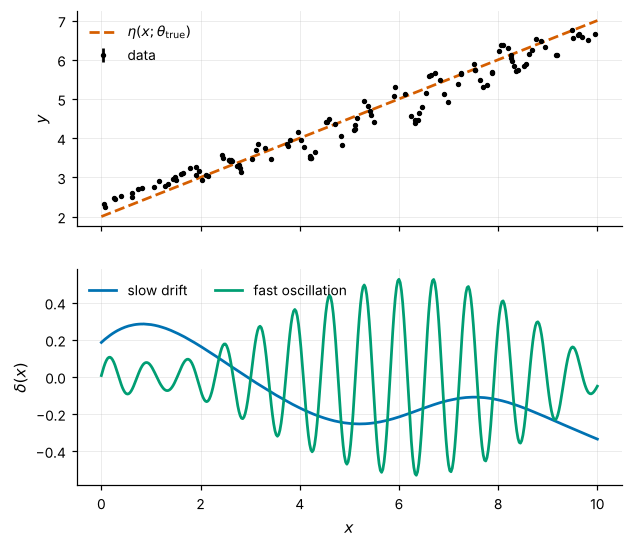

In [3]:
fig, (ax0, ax1) = plt.subplots(2, 1, figsize=(6.4, 5.6), sharex=True)
ax0.errorbar(x, y, sigma, fmt="o", color="k", ms=2.5, label="data")
ax0.plot(
    x_fine,
    h(x_fine) @ theta_true,
    "--",
    color=plotstyle.COLOURS[1],
    label=r"$\eta(x;\theta_{\rm true})$",
)
ax0.set(ylabel="$y$")
ax0.legend()
ax1.plot(x_fine, drift[n:], color=plotstyle.COLOURS[0], label="slow drift")
ax1.plot(x_fine, wiggle[n:], color=plotstyle.COLOURS[2], label="fast oscillation")
ax1.set(xlabel="$x$", ylabel=r"$\delta(x)$")
ax1.legend(ncol=2)
plt.show()

## One spectral-mixture component as an sklearn kernel

A single component with spectral mean $\mu$ and spectral standard deviation $s$ has the covariance

$$k(\tau) = \exp\!\left(-2\pi^2 s^2 \tau^2\right) \cos(2\pi\mu\tau),$$

the Fourier transform of a Gaussian at $\pm\mu$ with width $s$. $1/\mu$ is the period of the oscillation and $1/(2\pi s)$ the length of its envelope; $\mu = 0$ is the familiar squared-exponential kernel.

`T.kernel` accepts any object with sklearn's kernel interface, so a new kernel is a small `Kernel` subclass. The amplitude is left out: rxmc supplies it with `T.constant_amplitude`, exactly as for the built-in kernels. The two hyperparameters, `mu` and `s`, are declared with `Hyperparameter`, and sklearn samples them in log space.

In [4]:
class SpectralComponent(Kernel):
    r"""One spectral-mixture component, :math:`e^{-2\pi^2 s^2\tau^2}\cos(2\pi\mu\tau)`."""

    def __init__(self, mu=0.5, s=0.3, mu_bounds=(1e-3, 1e2), s_bounds=(1e-3, 1e2)):
        self.mu, self.s = mu, s
        self.mu_bounds, self.s_bounds = mu_bounds, s_bounds

    @property
    def hyperparameter_mu(self):
        return Hyperparameter("mu", "numeric", self.mu_bounds)

    @property
    def hyperparameter_s(self):
        return Hyperparameter("s", "numeric", self.s_bounds)

    def _k(self, X, Y):
        tau = X[:, :1] - Y[:, :1].T
        return np.exp(-2 * np.pi**2 * self.s**2 * tau**2) * np.cos(
            2 * np.pi * self.mu * tau
        )

    def __call__(self, X, Y=None, eval_gradient=False):
        if eval_gradient:
            raise NotImplementedError("rxmc never asks a kernel for gradients")
        X = np.atleast_2d(X)
        return self._k(X, X if Y is None else np.atleast_2d(Y))

    def diag(self, X):
        return np.ones(np.atleast_2d(X).shape[0])

    def is_stationary(self):
        return True


T.kernel_param_names(SpectralComponent())

['mu', 's']

sklearn orders a kernel's hyperparameters alphabetically by attribute name, not in the order of `__init__`. Here that happens to be `mu, s`; renaming `s` to `bandwidth` would reverse it. That is why `T.kernel` takes a kernel with more than one free hyperparameter's parameters as a mapping keyed by these names, and refuses a positional list.

## Priors, bounds, and the problem

We give the discrepancy $Q = 3$ components, one more than the truth has, to see whether the surplus switches off. Each component has three parameters, all sampled as logarithms:

- **the amplitude** $a_q$, with a half-Cauchy prior of scale 0.3, which puts mass near zero (a component can turn itself off) but has a heavy tail (it is not forbidden to matter). The half-Cauchy on $a$ is exactly a hyperbolic-secant distribution on $\log a$, so it is a plain scipy prior: if $a \sim {\rm HalfCauchy}(0, c)$ then $\log a$ has density $\operatorname{sech}(\log a - \log c)/\pi$;
- **the frequency** $\mu_q$ and **bandwidth** $s_q$, with wide log-normal priors.

The bounds are not decoration. The design can only resolve frequencies between roughly one cycle in five domains and the [Nyquist frequency](https://en.wikipedia.org/wiki/Nyquist_frequency) of the mean point spacing, and envelopes no shorter than about the spacing. A component outside that band is indistinguishable from the linear model (too slow) or from the noise (too fast), and its hyperparameters would wander there without bound.

In [5]:
Q = 3
log_mu_bounds = (np.log(0.2 / L), np.log(n / (2 * L)))  # period 50 ... Nyquist
log_s_bounds = (np.log(0.005), np.log(2.0))
log_a_bounds = (np.log(1e-3), np.log(10.0))

theta0 = rx.Parameter("theta0", prior=stats.norm(0.0, 10.0), latex=r"\theta_0")
theta1 = rx.Parameter("theta1", prior=stats.norm(0.0, 10.0), latex=r"\theta_1")
line = rx.Model(lambda x, theta0, theta1: theta0 + theta1 * x, [theta0, theta1])
comp = rx.Comparison(data, line)


def components(make_kernel):
    """Q kernel terms on `comp`, each with its own amplitude, frequency, bandwidth."""
    terms = []
    for q in range(Q):
        log_mu = rx.Parameter(
            f"log_mu{q}", bounds=log_mu_bounds, prior=stats.norm(np.log(0.5), 2.0)
        )
        log_s = rx.Parameter(
            f"log_s{q}", bounds=log_s_bounds, prior=stats.norm(np.log(0.3), 2.0)
        )
        log_a = rx.Parameter(
            f"log_a{q}", bounds=log_a_bounds, prior=stats.hypsecant(loc=np.log(0.3))
        )
        terms.append(
            T.kernel(
                make_kernel(),
                params={"mu": log_mu, "s": log_s},
                amplitude=T.constant_amplitude,
                amplitude_params=(log_a,),
                on=comp,
                jitter=1e-8,
            )
        )
    return terms


koh_terms = components(SpectralComponent)
koh = rx.Problem([rx.Constraint([comp], terms=koh_terms)])
print(koh)
print(koh.names)

Problem(ndim=11, constraints=1)
['theta0', 'theta1', 'log_mu0', 'log_s0', 'log_a0', 'log_mu1', 'log_s1', 'log_a1', 'log_mu2', 'log_s2', 'log_a2']


The constraint keeps its default `statistical=True`, so the reported $\sigma$ sits on the diagonal and the three components are added to it. This is the [Kennedy & O'Hagan (2001)](https://doi.org/10.1111/1467-9868.00294) model: $y = \eta(x;\theta) + \delta(x) + \varepsilon$ with $\delta = \sum_q \delta_q$ mean-zero, integrated out of the likelihood.

## Finding the posterior mode

The spectral-mixture likelihood is notoriously multimodal in the frequencies, so random restarts waste most of their effort. A better start reads the frequencies off the data. We fit the line by least squares and compute the [Lomb–Scargle periodogram](https://en.wikipedia.org/wiki/Least-squares_spectral_analysis) of the residuals, which handles unevenly spaced points, and put one component on each of its $Q$ largest well-separated peaks.

In [6]:
def periodogram_peaks(Q):
    """(frequency, amplitude) of the Q largest separated peaks of the OLS residual."""
    r = y - h(x) @ np.linalg.lstsq(h(x), y, rcond=None)[0]
    f = np.exp(np.linspace(*log_mu_bounds, 2000))
    P = lombscargle(x, r, 2 * np.pi * f, precenter=True)
    peaks = [i for i in range(1, f.size - 1) if P[i - 1] <= P[i] >= P[i + 1]]
    seeds = []
    for i in sorted(peaks, key=lambda i: -P[i]):
        if all(abs(np.log(f[i] / g)) > 0.3 for g, _ in seeds):
            seeds.append((f[i], np.sqrt(2 * P[i] / n)))
        if len(seeds) == Q:
            return seeds
    return seeds


seeds = periodogram_peaks(Q)
for f, a in seeds:
    print(f"peak at period {1 / f:6.2f}, amplitude ~ {a:.3f}")

peak at period   0.71, amplitude ~ 0.200
peak at period   8.17, amplitude ~ 0.090
peak at period   1.09, amplitude ~ 0.080


The two real scales are the two largest peaks: period about 0.71, and a slow mode at period about 8 that is the drift seen through a ten-unit window. The third peak, at period 1.09, is the surplus component's starting point.

From there we minimise $-\log p(\theta, \phi \mid y)$ with L-BFGS-B inside `problem.bounds` (recipe 33). The first start sits exactly on the peaks, with an envelope one spectral resolution wide; the others jitter it by a factor of about $e$.

In [7]:
def fit_map(problem, n_starts=6, seed=0):
    """Multistart L-BFGS-B from the periodogram seeds, inside problem.bounds."""
    r = np.random.default_rng(seed)
    names, bounds = problem.names, problem.bounds
    start = np.empty(problem.ndim)
    start[problem.columns(line.params)] = np.linalg.lstsq(h(x), y, rcond=None)[0]
    best = None
    for k in range(n_starts):
        t0 = start.copy()
        for q in range(Q):
            f, a = seeds[q % len(seeds)]
            jit = np.zeros(3) if k == 0 else r.normal(0.0, 1.0, 3)
            t0[names.index(f"log_mu{q}")] = np.log(f) + jit[0]
            t0[names.index(f"log_s{q}")] = np.log(1.0 / L) + jit[1]
            t0[names.index(f"log_a{q}")] = np.log(a) + jit[2]
        t0 = np.clip(t0, bounds[:, 0] + 1e-6, bounds[:, 1] - 1e-6)
        res = minimize(
            lambda t: -problem.log_posterior(t), t0, method="L-BFGS-B", bounds=bounds
        )
        if best is None or res.fun < best.fun:
            best = res
    return best.x


def describe(problem, terms, t):
    """One line per component: amplitude, period, envelope length."""
    for q, term in enumerate(terms):
        log_mu, log_s, log_a = t[problem.columns(term.params)]
        print(
            f"component {q}: amplitude {np.exp(log_a):.3f}   period "
            f"{np.exp(-log_mu):6.2f}   envelope {1 / (2 * np.pi * np.exp(log_s)):6.2f}"
        )

In [8]:
%%time
koh_map = fit_map(koh)
describe(koh, koh_terms, koh_map)
print("theta_hat =", koh_map[koh.columns(line.params)].round(3))

component 0: amplitude 0.178   period   0.72   envelope   9.24
component 1: amplitude 0.110   period   7.21   envelope  14.94
component 2: amplitude 0.161   period   0.68   envelope   5.93
theta_hat = [2.147 0.452]
CPU times: user 3min 6s, sys: 48.4 ms, total: 3min 6s
Wall time: 3min 8s


## What the components found

The learned spectral density is the sum of the components' Gaussians, weighted by $a_q^2$. The truth has one of its own: the drift is a Gaussian at zero frequency with width $1/(2\pi \cdot 2)$, and the oscillation a Gaussian at $1/0.7$ with width $1/(2\pi\cdot 3)$.

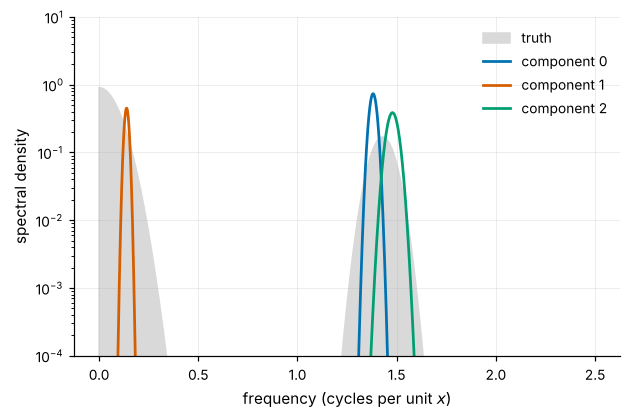

In [9]:
def spectrum(f, amp2, mu, s):
    """A symmetrised spectral Gaussian, on positive frequencies."""
    g = stats.norm(mu, s)
    return amp2 * (g.pdf(f) + g.pdf(-f))


f_grid = np.linspace(0.0, 2.5, 1500)
fig, ax = plt.subplots()
ax.fill_between(
    f_grid,
    spectrum(f_grid, 0.30**2, 0.0, 1 / (2 * np.pi * 2.0))
    + spectrum(f_grid, 0.15**2, 1 / 0.7, 1 / (2 * np.pi * 3.0)),
    color="0.85",
    label="truth",
)
for q, term in enumerate(koh_terms):
    log_mu, log_s, log_a = koh_map[koh.columns(term.params)]
    ax.plot(
        f_grid,
        spectrum(f_grid, np.exp(2 * log_a), np.exp(log_mu), np.exp(log_s)),
        label=f"component {q}",
    )
ax.set(
    xlabel="frequency (cycles per unit $x$)",
    ylabel="spectral density",
    yscale="log",
    ylim=(1e-4, 10),
)
ax.legend()
plt.show()

Both true scales are found, but not one component each. Component 1 carries the drift, as a narrow peak near frequency 0.14 rather than a broad peak at zero: over a window of five drift lengths the data contain about a cycle and a half of the drift, and a slow sinusoid fits that as well as a squared exponential does. The spectral *parameters* of a component whose scale is comparable to the window are not interpretable; only its existence is.

The surplus component did not switch off. Components 0 and 2 share the oscillation between them, at periods 0.72 and 0.68, both with large amplitudes. Splitting one real mode between two components costs almost nothing under a half-Cauchy amplitude prior, so the count of *distinct spectral modes* (two) is the meaningful number here, not the count of active components (three).

### Backing out each component

Because the discrepancy is a sum of independent GPs, each component has its own posterior given the data, with every other term of the covariance acting as noise:

$$\mathbb E[\delta_q \mid y] = K_q (K + \Sigma_{\rm exp})^{-1}(y - \eta(\hat\theta)).$$

That is what `gp_predictive_draws(..., terms=[term], conditioned=True)` computes, on any grid we bind the model to (recipe 40): its default conditioning noise is everything in the constraint except the chosen term. The bands below are conditional on the modal hyperparameters; we subtract the model's own prediction to leave $\delta_q$.

In [10]:
on_fine = line.bind(x_fine)


def component_bands(problem, terms, t):
    """(16, 50, 84) percentile bands of each delta_q on x_fine, at hyperparameters t."""
    eta = on_fine(*t[problem.columns(line.params)])
    return [
        rx.predictive.gp_predictive_draws(
            problem,
            term,
            on_fine,
            x_fine,
            t[None, :],
            terms=[term],
            conditioned=True,
            levels=(16, 50, 84),
            n_rep=400,
            rng=q,
        )
        - eta
        for q, term in enumerate(terms)
    ]


koh_bands = component_bands(koh, koh_terms, koh_map)

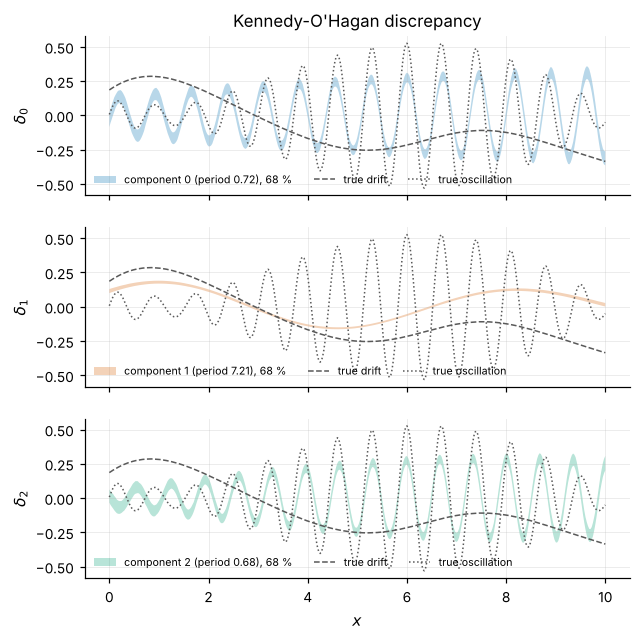

In [11]:
def plot_components(bands, t, problem, terms, title):
    fig, axes = plt.subplots(Q, 1, figsize=(6.4, 6.4), sharex=True, sharey=True)
    for q, (ax, band) in enumerate(zip(axes, bands)):
        period = np.exp(-t[problem.columns(terms[q].params)][0])
        plotstyle.band(
            ax,
            x_fine,
            band[0],
            band[2],
            color=plotstyle.COLOURS[q],
            label=f"component {q} (period {period:.2f}), 68 %",
        )
        ax.plot(x_fine, drift[n:], "--", color="0.35", lw=1, label="true drift")
        ax.plot(x_fine, wiggle[n:], ":", color="0.35", lw=1, label="true oscillation")
        ax.legend(fontsize=7, ncol=3, loc="lower left")
        ax.set(ylabel=rf"$\delta_{q}$")
    axes[0].set_title(title)
    axes[-1].set(xlabel="$x$")
    plt.show()


plot_components(koh_bands, koh_map, koh, koh_terms, "Kennedy-O'Hagan discrepancy")

Components 0 and 2 each carry part of the oscillation; their sum follows it. Component 1 follows the drift's shape but not its level: it sits offset and tilted against the true drift. That is not a failure of the component. It is the subject of the rest of this notebook.

## Which $\theta$ did we calibrate?

In [12]:
def laplace(problem, t, step=1e-4, tol=1e-3):
    """Inverse Hessian of -log posterior over the coordinates off the bounds.

    A hyperparameter that converged onto a bound has no Gaussian neighbourhood;
    it is held fixed, and the covariance is conditional on it.
    """
    lo, hi = problem.bounds[:, 0], problem.bounds[:, 1]
    free = np.flatnonzero(np.minimum(t - lo, hi - t) > tol)
    f = lambda v: -problem.log_posterior(v)
    E = np.zeros((free.size, t.size))
    E[np.arange(free.size), free] = step
    H = np.array(
        [
            [f(t + a + b) - f(t + a - b) - f(t - a + b) + f(t - a - b) for b in E]
            for a in E
        ]
    ) / (4 * step**2)
    cov = np.full((t.size, t.size), np.nan)
    cov[np.ix_(free, free)] = np.linalg.inv(0.5 * (H + H.T))
    pinned = [problem.names[i] for i in range(t.size) if i not in free]
    return cov, pinned


def report(problem, t, label):
    cov, pinned = laplace(problem, t)
    cols = problem.columns(line.params)
    th, C = t[cols], cov[np.ix_(cols, cols)]
    sd = np.sqrt(np.diag(C))
    print(f"{label}: theta_hat = {th.round(3)} +/- {sd.round(3)}")
    if pinned:
        print("   on a bound, held fixed:", pinned)
    for name, ref in [("theta_true", theta_true), ("theta*", theta_star)]:
        d = th - ref
        print(
            f"   Mahalanobis distance to {name:10s}: {np.sqrt(d @ np.linalg.solve(C, d)):6.2f}"
        )
    return th, C

The truth is $\theta = (2, 0.5)$, and the fit will not land there. Any discrepancy can be split into a part the line can represent and a part it cannot. The likelihood sees only $\eta + \delta$, so it has no way to assign the first part to $\delta$ rather than to $\theta$. What the data *can* pin down is the projection of reality onto the model,

$$\theta^\ast = \arg\min_\theta \int_0^{10} \big(\zeta(x) - \eta(x;\theta)\big)^2\, dx, \qquad \zeta = \eta(\cdot\,;\theta_{\rm true}) + \delta,$$

which we can compute here because we know $\delta$ on the fine grid.

In [13]:
w = np.full(x_fine.size, x_fine[1] - x_fine[0])
w[[0, -1]] *= 0.5  # trapezoid
G = h(x_fine).T @ (w[:, None] * h(x_fine))
theta_star = theta_true + np.linalg.solve(G, h(x_fine).T @ (w * delta_true[n:]))
print("theta_true =", theta_true, "   theta* =", theta_star.round(3))
koh_theta, koh_cov = report(koh, koh_map, "Kennedy-O'Hagan")

theta_true = [2.  0.5]    theta* = [2.203 0.445]


Kennedy-O'Hagan: theta_hat = [2.147 0.452] +/- [0.023 0.004]
   Mahalanobis distance to theta_true:  18.74
   Mahalanobis distance to theta*    :   4.41


Read at face value, the Laplace approximation puts $\theta_{\rm true}$ almost twenty standard deviations away, and $\theta^\ast$ more than four. The first is no surprise: $\theta_{\rm true}$ differs from $\theta^\ast$ by the part of $\delta$ that the line can imitate, and nothing in any likelihood can recover it. The second says the mode does not hit $\theta^\ast$ either. Under the Kennedy–O'Hagan prior, the mode lands wherever the fitted kernel happens to split the line-like part of the residual between $\delta$ and $\theta$; change the kernel family or its priors, and it moves. The estimate has no well-defined target. (We will also see, when we sample, that this error bar is far too small.)

## Plumlee's orthogonal discrepancy

[Plumlee (2017)](https://doi.org/10.1080/01621459.2017.1329149) removes the ambiguity by forbidding the discrepancy from containing anything the model can do. The prior on $\delta$ is conditioned on

$$\int_0^{10} \delta(x)\, \frac{\partial\eta}{\partial\theta}(x)\, dx = 0,$$

which for our line means $\delta$ is $L^2$-orthogonal to both $1$ and $x$. Conditioning a GP on a linear functional is again a GP, with the kernel

$$k^\perp(x, x') = k(x, x') - g(x)^\top M^{-1} g(x'), \qquad g(x) = \int k(x, u)\, h(u)\, du, \qquad M = \iint h(u)\, k(u, u')\, h(u')^\top du\, du'.$$

Under this prior, $\theta$ *is* $\theta^\ast$ by construction.

It is still a kernel of $x$, so it is still an sklearn kernel and still a `T.kernel` term, and it still travels to a prediction grid. We orthogonalise each component separately, so the decomposition into components stays exact. The integrals use [Gauss–Legendre](https://en.wikipedia.org/wiki/Gauss%E2%80%93Legendre_quadrature) quadrature with a node count that follows the component's spectrum, since the integrand oscillates at $\mu$ under an envelope of width $s$; a fixed rule accurate for the drift would alias the oscillation.

In [14]:
@lru_cache(maxsize=64)
def gauss_legendre(n_nodes, lo, hi):
    t, wt = np.polynomial.legendre.leggauss(n_nodes)
    return 0.5 * (hi - lo) * (t + 1) + lo, 0.5 * (hi - lo) * wt


class OrthogonalSpectralComponent(SpectralComponent):
    """A spectral component conditioned on int delta h dx = 0 over [lo, hi]."""

    def __init__(
        self, mu=0.5, s=0.3, mu_bounds=(1e-3, 1e2), s_bounds=(1e-3, 1e2), lo=0.0, hi=L
    ):
        super().__init__(mu, s, mu_bounds, s_bounds)
        self.lo, self.hi = lo, hi

    def __call__(self, X, Y=None, eval_gradient=False):
        if eval_gradient:
            raise NotImplementedError("rxmc never asks a kernel for gradients")
        X = np.atleast_2d(X)
        Y = X if Y is None else np.atleast_2d(Y)
        width = self.hi - self.lo
        n_nodes = int(
            np.clip(np.ceil(4 * width * (self.mu + 2 * self.s)) + 16, 32, 400)
        )
        u, wu = gauss_legendre(n_nodes, self.lo, self.hi)
        U, Hw = u[:, None], wu[:, None] * h(u)
        gX, gY = self._k(X, U) @ Hw, self._k(Y, U) @ Hw
        M = Hw.T @ self._k(U, U) @ Hw
        return self._k(X, Y) - gX @ np.linalg.solve(M, gY.T)

    def diag(self, X):
        return np.diag(self(X))

    def is_stationary(self):
        return False


plumlee_terms = components(OrthogonalSpectralComponent)
plumlee = rx.Problem([rx.Constraint([comp], terms=plumlee_terms)])

Everything else is unchanged: the same line, the same data, the same priors and bounds, the same starts.

In [15]:
%%time
plumlee_map = fit_map(plumlee)
describe(plumlee, plumlee_terms, plumlee_map)
plumlee_theta, plumlee_cov = report(plumlee, plumlee_map, "Plumlee")

component 0: amplitude 0.137   period   9.57   envelope   5.06
component 1: amplitude 0.351   period   0.71   envelope   3.37
component 2: amplitude 0.024   period   0.42   envelope   4.48


Plumlee: theta_hat = [2.204 0.447] +/- [0.01  0.002]
   Mahalanobis distance to theta_true:  33.97
   Mahalanobis distance to theta*    :   2.20
CPU times: user 5min 6s, sys: 57.8 ms, total: 5min 6s
Wall time: 5min 9s


The orthogonal fit lands on $\theta^\ast$, about two standard deviations away, with a smaller error bar than the Kennedy–O'Hagan fit. It is no closer to $\theta_{\rm true}$, and could not be: orthogonality changes what $\theta$ *means*, it does not add information. What it buys is an estimator with a definite target, and error bars that describe the distance to that target.

The components rearrange too: one slow component, one fast one carrying almost all of the oscillation, and a third with less than a tenth of its amplitude. Below we compare the *total* discrepancy each fit reconstructs.

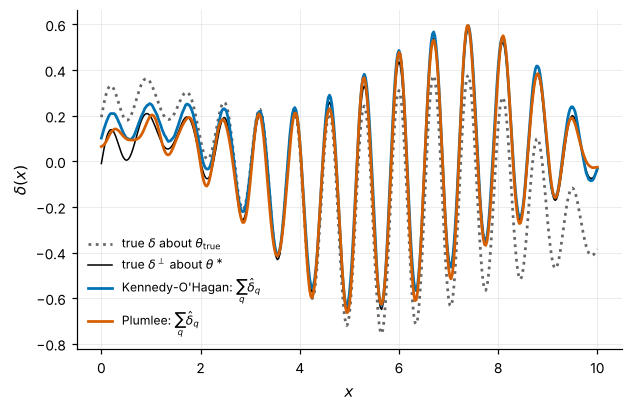

In [16]:
plumlee_bands = component_bands(plumlee, plumlee_terms, plumlee_map)
delta_perp = delta_true[n:] - h(x_fine) @ (theta_star - theta_true)
fig, ax = plt.subplots()
ax.plot(
    x_fine,
    delta_true[n:],
    ":",
    color="0.4",
    label=r"true $\delta$ about $\theta_{\rm true}$",
)
ax.plot(
    x_fine,
    delta_perp,
    color="k",
    lw=1,
    label=r"true $\delta^\perp$ about $\theta^\ast$",
)
for i, (label, bands) in enumerate(
    [("Kennedy-O'Hagan", koh_bands), ("Plumlee", plumlee_bands)]
):
    ax.plot(
        x_fine,
        sum(b[1] for b in bands),
        color=plotstyle.COLOURS[i],
        label=rf"{label}: $\sum_q \hat\delta_q$",
    )
ax.set(xlabel="$x$", ylabel=r"$\delta(x)$")
ax.legend(fontsize=8)
plt.show()

Both fits reconstruct the *total* discrepancy about their own $\hat\theta$ well, and both follow $\delta^\perp$ rather than the $\delta$ we drew: the data never knew which line we started from.

## Checking the Laplace approximation with a chain

Recipe 33 says to compare a Laplace covariance against a chain before reporting it. We run an [emcee](https://emcee.readthedocs.io/) chain from a small ball around each mode and print its integrated autocorrelation time $\tau$, the number of steps between effectively independent samples.

In [17]:
def chain(problem, t, n_steps=1500, n_walkers=24, seed=0):
    lo, hi = problem.bounds[:, 0], problem.bounds[:, 1]
    r = np.random.default_rng(seed)
    start = np.clip(
        t + 1e-3 * r.standard_normal((n_walkers, t.size)), lo + 1e-9, hi - 1e-9
    )
    sampler = emcee.EnsembleSampler(n_walkers, problem.ndim, problem.log_posterior)
    sampler.random_state = np.random.RandomState(seed).get_state()
    sampler.run_mcmc(start, n_steps, progress=False)
    tau = sampler.get_autocorr_time(tol=0).max()  # a lower bound from a short chain
    print(
        f"acceptance {sampler.acceptance_fraction.mean():.2f}, "
        f"longest tau {tau:.0f} steps: {n_steps / tau:.0f} tau in the chain"
    )
    return sampler.get_chain(discard=500, thin=5, flat=True)

In [18]:
%%time
koh_chain = chain(koh, koh_map)
plumlee_chain = chain(plumlee, plumlee_map)

acceptance 0.28, longest tau 141 steps: 11 tau in the chain


acceptance 0.29, longest tau 168 steps: 9 tau in the chain
CPU times: user 6min 53s, sys: 119 ms, total: 6min 53s
Wall time: 6min 58s


Kennedy-O'Hagan  chain   [2.084 0.462] +/- [0.1731 0.0252]
                 Laplace [2.147 0.452] +/- [0.0226 0.0045]
Plumlee          chain   [2.202 0.447] +/- [0.0102 0.0018]
                 Laplace [2.204 0.447] +/- [0.01   0.0017]


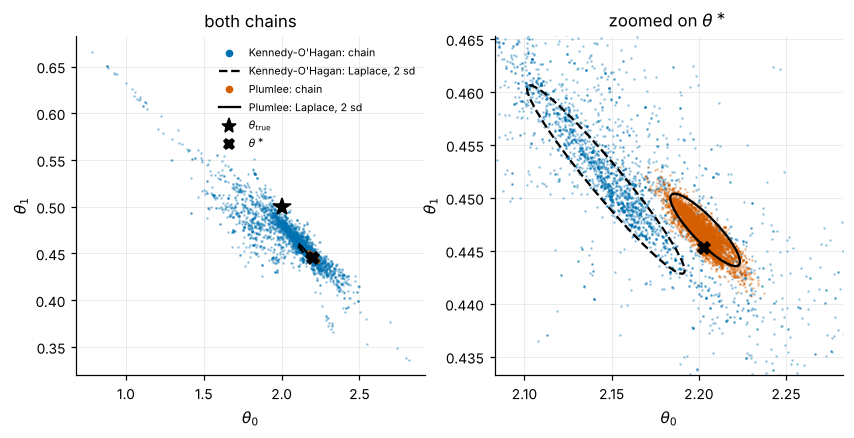

In [19]:
cols = koh.columns(line.params)
for label, ch, th, C in [
    ("Kennedy-O'Hagan", koh_chain, koh_theta, koh_cov),
    ("Plumlee", plumlee_chain, plumlee_theta, plumlee_cov),
]:
    s = ch[:, cols]
    print(f"{label:16s} chain   {s.mean(0).round(3)} +/- {s.std(0).round(4)}")
    print(f"{'':16s} Laplace {th.round(3)} +/- {np.sqrt(np.diag(C)).round(4)}")


def ellipse(ax, mean, cov, k, **kwargs):
    """The k-sigma ellipse of a 2-D Gaussian."""
    vals, vecs = np.linalg.eigh(cov)
    angle = np.degrees(np.arctan2(vecs[1, 1], vecs[0, 1]))
    width, height = 2 * k * np.sqrt(vals[1]), 2 * k * np.sqrt(vals[0])
    ax.add_patch(Ellipse(mean, width, height, angle=angle, fill=False, **kwargs))


fig, (wide, zoom) = plt.subplots(1, 2, figsize=(9.0, 4.0))
runs = [
    ("Kennedy-O'Hagan", koh_chain, koh_theta, koh_cov, "--"),
    ("Plumlee", plumlee_chain, plumlee_theta, plumlee_cov, "-"),
]
for ax in (wide, zoom):
    for i, (label, ch, th, C, ls) in enumerate(runs):
        ax.plot(*ch[:, cols].T, ".", ms=1.5, alpha=0.3, color=plotstyle.COLOURS[i])
        ellipse(ax, th, C, 2, color="k", ls=ls, lw=1.5, zorder=3)
    ax.plot(*theta_true, "*", color="k", ms=12)
    ax.plot(*theta_star, "X", color="k", ms=8)
    ax.set(xlabel=r"$\theta_0$", ylabel=r"$\theta_1$")
for i, (label, _, _, _, ls) in enumerate(runs):  # legend proxies
    wide.plot([], [], "o", ms=4, color=plotstyle.COLOURS[i], label=f"{label}: chain")
    wide.plot([], [], ls, color="k", lw=1.5, label=f"{label}: Laplace, 2 sd")
wide.plot([], [], "*", color="k", ms=10, label=r"$\theta_{\rm true}$")
wide.plot([], [], "X", color="k", ms=7, label=r"$\theta^\ast$")
wide.legend(fontsize=7)
wide.set(title="both chains")
zoom.set(
    xlim=theta_star[0] + np.array([-0.12, 0.08]),
    ylim=theta_star[1] + np.array([-0.012, 0.02]),
    title=r"zoomed on $\theta^\ast$",
)
plt.show()

The two models behave completely differently.

Both chains are short: about ten autocorrelation times each, and an autocorrelation time estimated from a short chain is itself an underestimate. The hyperparameters mix slowly in both. What that costs depends on how much $\theta$ cares about them.

- **Plumlee**: the chain and the Laplace ellipse agree, and both sit on $\theta^\ast$. With the discrepancy forbidden from imitating the line, $\theta$ barely moves as the hyperparameters wander, so it is sharply identified and the Laplace approximation is good enough.
- **Kennedy–O'Hagan**: the chain is several times wider than the Laplace ellipse, stretched along a ridge of anticorrelated intercept and slope, and it reaches $\theta_{\rm true}$. Being short, it *understates* the width: a run four times longer with more walkers (not executed here) has an autocorrelation time near 400 steps and a standard deviation of 0.28 in $\theta_0$, more than ten times the Laplace value. The data fix $\theta$ only up to what the slow component can absorb, and the posterior spreads along that trade-off, with its extent set by the prior on $\delta$ rather than by the data.

So the Kennedy–O'Hagan posterior covers $\theta_{\rm true}$, but not because it learned anything about it: it is wide because $\theta$ is not identified. A MAP-and-Laplace summary of the same posterior was wrong twice, in location and in width.


## What to take from this

- **A spectral mixture detects scales, not mechanisms.** Two scales an order of magnitude apart, each inside the band the design resolves, came out as two distinct spectral modes. A scale near the window length is detected but its spectral parameters are not meaningful, and a scale shorter than the point spacing would be indistinguishable from noise without replicates or a known experimental covariance.
- **Surplus components do not reliably switch off.** Here the third component split the oscillation with another rather than vanishing. A half-Cauchy amplitude prior allows a component to vanish but does not force it to. Count distinct spectral modes, not active components, or use a prior that favours few components.
- **The calibrated $\theta$ is the projection $\theta^\ast$ at best.** Under Kennedy–O'Hagan, $\theta$ has no defined target: its posterior is wide, slow to sample, and shaped by the prior on $\delta$, and a Laplace approximation at the mode hides all three. Plumlee's orthogonality gives $\theta$ a target, and its error bars then describe the distance to it. Recovering more of $\theta_{\rm true}$ needs information about $\delta$ in the span of $\partial\eta/\partial\theta$, which the data cannot provide: a physics prior on the form of the defect, or several observables that share $\theta$ but not $\delta$.
- **The measure in the orthogonality condition is a modelling choice.** $\theta^\ast$ depends on the domain and its weighting: uniform in angle, uniform in $\cos\theta$ and the experimental design density give three different "physical" parameters.
- **A nonlinear model makes $k^\perp$ depend on $\theta$**, since $h = \partial\eta/\partial\theta$ does. The kernel must then be rebuilt at each $\theta$, which is natural when the model is differentiable and $h$ is its Jacobian.